<a href="https://colab.research.google.com/github/tustus1022-ui/esaa/blob/main/ESAA_OB_WEEK10_transcription_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<딥러닝 파이토치 교과서> 5장 p.179-200 필사

## **5.2 합성곱 신경망 맛보기**
fashion_mnist 데이터셋으로 합성곱 신경망을 직접 구현하고, 합성곱이 아닌 심층 신경망(DNN)과 성능을 비교함.

**fashion_mnist 데이터셋**
- 토치비전(torchvision)에 내장된 예제 데이터. 운동화, 셔츠, 샌들 같은 작은 이미지 모음
- 28×28 픽셀 이미지 7만 개로 구성되며, MNIST처럼 10가지로 분류됨
- 훈련 데이터(train_images): 0~255 값을 갖는 28×28 크기의 넘파이 배열
- 레이블 데이터(train_labels): 0~9 정수 값을 갖는 배열로, 이미지의 클래스를 나타냄
    - 0: T-Shirt, 1: Trouser, 2: Pullover, 3: Dress, 4: Coat, 5: Sandal, 6: Shirt, 7: Sneaker, 8: Bag, 9: Ankle Boot

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.autograd import Variable
import torch.nn.functional as F

import torchvision
import torchvision.transforms as transforms # 데이터 전처리를 위해 사용하는 라이브러리
from torch.utils.data import Dataset, DataLoader

**CPU / GPU 사용**
- 파이토치는 기본적으로 GPU 사용을 권장하지만, GPU가 없는 환경에서도 정상적으로 실행됨
- GPU가 장착되어 있고 사용 설정이 되어 있으면 파이토치가 자동으로 인식함
- GPU 하나를 쓸 때는 device를 지정하고 모델을 그 device로 보냄
- GPU 여러 개를 쓸 때는 **nn.DataParallel** 사용
    - 배치 크기가 각 GPU에 자동으로 분배되므로, GPU 수만큼 배치 크기도 늘려야 함

In [2]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

**데이터 내려받기와 데이터로더**
- torchvision.datasets: torch.utils.data.Dataset의 하위 클래스로, CIFAR, COCO, MNIST, ImageNet 등 다양한 데이터셋을 포함함
    - 첫 번째 파라미터: 데이터셋을 내려받을 위치
    - download: True면 지정한 위치에 데이터셋이 있는지 확인한 뒤 내려받음
    - transform: 이미지를 텐서(0~1)로 바꿈
- torch.utils.data.DataLoader: 원하는 크기의 배치 단위로 데이터를 불러오거나 순서를 무작위로 섞을(shuffle) 수 있음
    - 첫 번째 파라미터: 데이터를 불러올 데이터셋
    - batch_size: 데이터를 묶는 단위(예: 100이면 100개씩 묶어서 불러옴)

In [3]:
train_dataset = torchvision.datasets.FashionMNIST(".. /chap05/data", download=True,
                            transform=transforms.Compose([transforms.ToTensor()]))
test_dataset = torchvision.datasets.FashionMNIST(".. /chap05/data", download=True,
                            train=False, transform=transforms.Compose([transforms.ToTensor()]))

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 171kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.08MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 12.3MB/s]


In [4]:
train_loader = torch.utils.data.DataLoader(train_dataset,
                                           batch_size=100) # (1)
test_loader = torch.utils.data.DataLoader(test_dataset,
                                          batch_size=100)

**넘파이 난수 함수**
- np.random.randint(): 이산형 분포에서 무작위 표본을 추출. randint(10)은 0~9, randint(1, 10)은 1~9 중 임의의 숫자
- np.random.rand(): 0~1 사이의 균등분포 난수를 원하는 행렬 크기로 출력 (교재에는 '정규표준분포'라고 적혀 있지만 실제로는 균등분포임)
- np.random.randn(): 평균이 0이고 표준편차가 1인 가우시안 정규분포 난수를 원하는 행렬 크기로 출력

**배열 인덱싱**
- examp[3]: 3행의 모든 요소 / examp[3, 3]과 examp[3][3]: 3행 3열의 요소 (행과 열은 0부터 시작)
- train_dataset[img_xy][0][0, :, :]: train_dataset에서 img_xy번째 데이터의 이미지(0번 요소)를 가져와 첫 번째 채널의 2차원 이미지만 꺼낸다는 의미

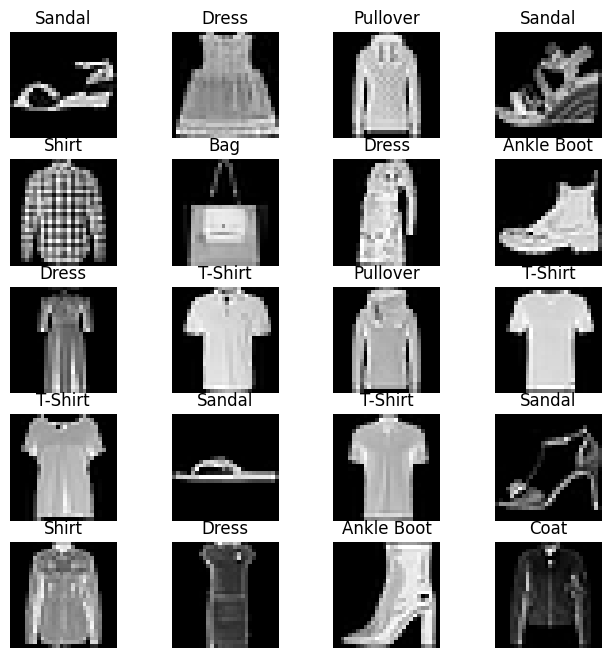

In [5]:
labels_map = {0: 'T-Shirt', 1: 'Trouser', 2: 'Pullover', 3: 'Dress', 4:'Coat',
              5: 'Sandal', 6: 'Shirt', 7: 'Sneaker', 8: 'Bag', 9: 'Ankle Boot'}

fig = plt.figure(figsize=(8,8));
columns = 4;
rows = 5;
for i in range(1, columns*rows +1):
    img_xy = np.random.randint(len(train_dataset));
    img = train_dataset[img_xy][0][0,:,:]
    fig.add_subplot(rows, columns, i)
    plt.title(labels_map[train_dataset[img_xy][1]])
    plt.axis('off')
    plt.imshow(img, cmap='gray')
plt.show()

In [6]:
class FashionDNN(nn.Module):
    def __init__(self):  # (1)
        super(FashionDNN, self).__init__()
        self.fc1 = nn.Linear(in_features=784, out_features=256)  # (2)
        self.drop = nn.Dropout(0.25) # (3)
        self.fc2 = nn.Linear(in_features=256, out_features=128)
        self.fc3 = nn.Linear(in_features=128, out_features=10)

    def forward(self, input_data):     # (4)
        out = input_data.view(-1, 784) # (5)
        out = F.relu(self.fc1(out))    # (6)
        out = self.drop(out)
        out = F.relu(self.fc2(out))
        out = self.fc3(out)
        return out

### **심층 신경망(DNN) 모델 생성**
**클래스 형태 모델의 기본 구조**
- 클래스 형태의 모델은 항상 **torch.nn.Module**을 상속받음
- __init__(): 객체가 갖는 속성 값을 초기화하며, 객체가 생성될 때 자동으로 호출됨
- super(클래스명, self).__init__(): nn.Module 클래스를 상속받겠다는 의미

**객체**
- 파이토치의 근간은 C++이므로, C++의 객체 지향 프로그래밍 특징을 파이토치에서도 사용함
- 객체 지향 프로그래밍: 데이터를 추상화해 속성, 행동, 특징 등을 객체로 만들고, 객체들이 서로 유기적으로 동작하도록 하는 프로그래밍 방법
    - 클래스라는 붕어빵 틀에서 객체라는 붕어빵을 여러 개 찍어 내는 것과 같음 → 재사용성 때문에 많이 사용
- 객체(object): 메모리를 할당받아 프로그램에서 사용되는 모든 데이터. 변수, 함수 등은 모두 객체임
- 사용 방법: 객체명 = 클래스명()

**클래스와 함수**
- 함수(function): 하나의 특정 작업을 수행하도록 독립적으로 설계된 코드. 결괏값을 계속 쓰려면 따로 저장해야 함
- 클래스(class): 함수뿐만 아니라 관련 변수까지 한꺼번에 묶어서 관리하고 재사용할 수 있게 해 줌
- 같은 클래스로 만든 두 객체는 서로 독립적으로 연산됨 → 코드가 간결해짐

**주요 구성 요소**
- nn: 딥러닝 모델(네트워크) 구성에 필요한 모듈이 모여 있는 패키지
- nn.Linear: 단순 선형 회귀 모델을 만들 때 사용
    - in_features: 입력의 크기 / out_features: 출력의 크기
    - forward()에는 입력만 넘겨주고, out_features에서 정한 크기가 연산 결과가 됨
- nn.Dropout(p): p의 비율로 텐서 값이 0이 되고, 0이 되지 않은 값들은 1/(1−p)배만큼 커짐
    - 예) p=0.3이면 전체 값 중 30%가 0이 되고, 나머지 70%는 1/(1−0.7)배만큼 커짐
- forward(): 모델이 학습 데이터를 입력받아 순전파 연산을 진행하는 함수
    - 반드시 forward라는 이름이어야 함
    - 객체를 데이터와 함께 호출하면 자동으로 실행됨
    - 순전파 연산: H(x) 식에 입력 x를 넣어 예측된 y를 얻는 것 (H(x)는 각 모델의 활성화 함수와 입력값에 따라 달라짐)
- view() (p.189): 넘파이의 reshape처럼 텐서의 크기(shape)를 바꿈
    - view(-1, 784): (?, 784) 크기의 2차원 텐서로 바꾸라는 의미
    - -1은 해당 차원의 크기를 파이토치가 알아서 정하게 맡긴다는 의미

**활성화 함수 지정 방법**
- F.relu(): forward() 함수 안에서 정의
- nn.ReLU(): __init__() 함수 안에서 정의
- 활성화 함수만 놓고 보면 차이는 사용하는 위치뿐이지만, 근본적으로 nn.xx와 nn.functional.xx는 사용 방법이 다름

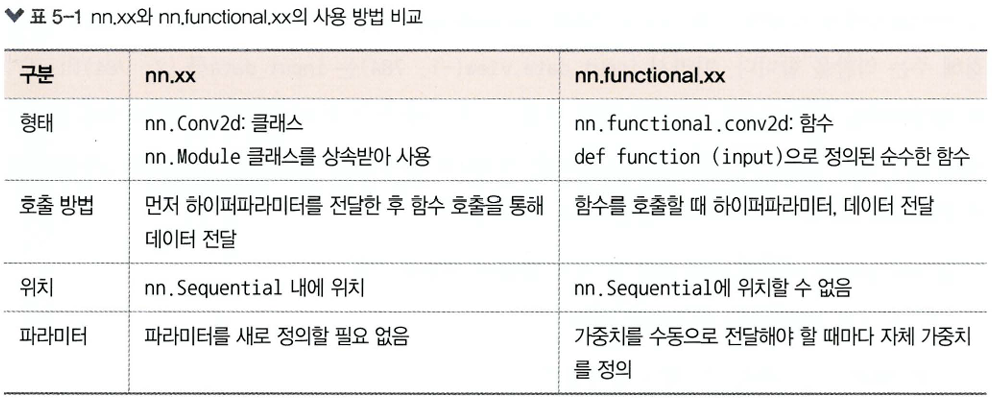

### **심층 신경망 학습**
**학습 전 정의할 것**
- 손실 함수: CrossEntropyLoss (분류 문제에서 사용)
- 옵티마이저: Adam, 학습률(lr) 0.001

In [7]:
learning_rate = 0.001;
model = FashionDNN();
model.to(device)

criterion = nn.CrossEntropyLoss (); # 분류 문제에서 사용하는 손실 함수
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate);
print(model)

FashionDNN(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (drop): Dropout(p=0.25, inplace=False)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=10, bias=True)
)


In [8]:
num_epochs = 5
count = 0

loss_list = []
iteration_list = []
accuracy_list = []

predictions_list = []
labels_list = []

for epoch in range(num_epochs):
  for images, labels in train_loader:
      images, labels = images.to(device), labels.to(device)

      train = Variable(images.view(100, 1, 28, 28))
      labels = Variable(labels)

      outputs = model(train) # 학습 데이터를 모델에 적용
      loss = criterion(outputs, labels)
      optimizer.zero_grad()
      loss.backward()
      optimizer.step()
      count += 1

      if not (count % 50): # count를 50으로 나누었을 때 나머지가 0이 아니라면 실행
        total = 0
        correct = 0
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            labels_list.append(labels)
            test = Variable(images.view(100, 1, 28, 28))
            outputs = model(test)
            predictions = torch.max(outputs, 1)[1].to(device)
            predictions_list.append(predictions)
            correct += (predictions == labels).sum()
            total += len(labels)

        accuracy = correct * 100 / total
        loss_list.append(loss. data)
        iteration_list.append(count)
        accuracy_list.append(accuracy)

      if not (count % 500):
         print("Iteration: {}, Loss: {}, Accuracy: {}%" .format(count, loss.data,
                                                             accuracy))

Iteration: 500, Loss: 0.5435903072357178, Accuracy: 83.05999755859375%
Iteration: 1000, Loss: 0.449718713760376, Accuracy: 84.93999481201172%
Iteration: 1500, Loss: 0.3329901099205017, Accuracy: 84.20999908447266%
Iteration: 2000, Loss: 0.33320388197898865, Accuracy: 85.20999908447266%
Iteration: 2500, Loss: 0.27262645959854126, Accuracy: 86.48999786376953%
Iteration: 3000, Loss: 0.28763347864151, Accuracy: 86.72999572753906%


**학습 과정의 핵심 개념**
- 리스트 사용: 빈 배열을 만든 뒤 append 메서드로 데이터를 하나씩 추가함
- for x, y in train: 레코드(행)를 하나씩 가져오며, in 앞에 변수를 두 개 두면 요소 두 개를 꺼내 옴
- 모델과 데이터는 같은 장치(CPU 또는 GPU)에 있어야 함
    - 모델을 GPU에 올렸다면 이미지와 레이블도 GPU로 보내야 함
    - CPU 데이터를 GPU 모델에 넣거나 그 반대면 런타임 오류가 발생함
- Autograd: 자동 미분을 수행하는 파이토치의 핵심 패키지
    - 자동 미분 값을 저장하기 위해 테이프(tape)를 사용함
    - 순전파 단계에서 테이프가 모든 연산을 저장하고, 역전파 단계에서 저장된 값을 꺼내 사용함
    - torch.autograd 패키지의 Variable을 사용해 역전파용 미분 값을 자동으로 계산함

**분류 문제의 정확도**
- 정확도 = 정확한 예측 수 / 전체 예측 수 (×100을 하면 백분율)
- 오류율(오분류율) = (1 − 정확한 예측 수 / 전체 예측 수) × 100
- 클래스가 세 개 이상일 때 주의할 점
    - 정확도가 80%여도 모든 클래스를 고르게 맞힌 것인지, 특정 클래스만 잘 맞힌 것인지 알 수 없음
    - 100개 중 90개가 한 클래스에 속하면, 모두 그 클래스로 예측해도 정확도가 90%가 나옴 → 데이터 특성에 따라 정확도를 잘 살펴봐야 함

**결과**: DNN의 최종 정확도는 약 86%

### **합성곱 신경망(CNN) 모델 생성**

**nn.Sequential**
- __init__()에서 사용할 네트워크 모델을 정의하고, forward()에서 구현할 순전파를 계층 형태로 가독성 있게 작성할 수 있음
- Wx + b 같은 수식과 활성화 함수를 연결해 계층을 차례로 쌓을 수 있게 해 줌
- 데이터가 각 계층을 순서대로 지나갈 때 쓰면 좋음
- 즉, 여러 계층을 하나의 컨테이너에 구현하는 방법

In [9]:
class FashionCNN(nn.Module):
    def __init__(self):
        super(FashionCNN, self).__init__()
        self.layer1 = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.layer2 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.fc1 = nn.Linear(in_features=64*6*6, out_features=600)
        self.drop = nn.Dropout(0.25)
        self.fc2 = nn.Linear(in_features=600, out_features=120)
        self.fc3 = nn.Linear(in_features=120, out_features=10)

    def forward(self, x):
        out = self.layer1(x)
        out = self.layer2(out)
        out = out.view(out.size(0), -1)
        out = self.fc1(out)
        out = self.drop(out)
        out = self.fc2(out)
        out = self.fc3(out)
        return out

**합성곱층(Conv2d)**
- 합성곱 연산으로 이미지의 특징을 추출함
- 합성곱: 커널(필터)이라는 n×m 행렬이 높이×너비 크기의 이미지를 처음부터 끝까지 훑으면서, 원소끼리 곱한 뒤 모두 더한 값을 출력하는 것
- 커널은 보통 3×3이나 5×5를 사용
- 파라미터
    - in_channels: 입력 채널 수 (흑백 이미지는 1, RGB 이미지는 3인 경우가 많음)
    - out_channels: 출력 채널 수
    - kernel_size: 커널 크기(논문에 따라 필터라고도 함)
        - 커널은 이미지 특징을 찾기 위한 공용 파라미터이며, CNN에서 학습 대상은 필터 파라미터
        - 커널은 입력 데이터를 스트라이드 간격으로 순회하며 합성곱을 계산함
        - kernel_size=3이면 (3, 3) 정사각형, 직사각형을 쓰려면 (3, 5)처럼 지정
    - padding: 출력 크기를 조정하기 위해 입력 데이터 주위를 0으로 채움. 패딩 값이 클수록 출력 크기도 커짐
- 채널
    - 흑백 이미지는 w×h 행렬로 표현됨
    = 컬러 이미지는 Red, Green, Blue 세 채널을 가지며 w×h×c 행렬로 표현됨(c는 채널 수)
    - 3차원으로 보면 채널은 깊이(depth)를 의미함

**BatchNorm2d**
- 학습 과정에서 배치마다 데이터 분포가 달라도 평균과 분산을 이용해 정규화함
- 배치나 계층에 따라 입력값 분포가 달라도, 정규화로 분포를 가우시안 형태(평균 0, 표준편차 1)로 맞춤

**MaxPool2d (풀링 계층)**
- 이미지 크기를 줄이는 용도로 사용
- 합성곱층의 출력 데이터를 입력받아 출력 데이터(activation map)의 크기를 줄이거나 특정 데이터를 강조함
- 풀링 방법: 최대 풀링, 평균 풀링, 최소 풀링
- 파라미터
    - kernel_size: m×n 행렬로 구성된 가중치
    - stride: 입력 데이터에 커널을 적용할 때 이동하는 간격. 스트라이드가 커질수록 출력 크기는 작아짐

**완전연결층(fully connected layer)**
- 클래스를 분류하려면 이미지 형태의 데이터를 배열 형태로 바꿔야 함
- Conv2d의 하이퍼파라미터(패딩, 스트라이드)에 따라 출력 크기가 달라지고, 줄어든 출력은 최종적으로 분류를 담당하는 완전연결층으로 전달됨
- Conv2d, MaxPool2d는 이미지 데이터를 처리하지만, 완전연결층으로 보내려면 1차원으로 바꿔야 함
- in_features: 입력 데이터의 크기 / out_features: 출력 데이터의 크기
- 마지막 계층의 out_features는 클래스 개수를 의미함

**출력 크기 계산 공식**
- Conv2d: 출력 크기 = (W − F + 2P) / S + 1
    - W: 입력 데이터 크기, F: 커널 크기, P: 패딩 크기, S: 스트라이드
    - stride를 지정하지 않으면 기본값은 (1, 1)
    - 예) 첫 번째 Conv2d: (28 − 3 + 2×1) / 1 + 1 = 28 → 출력 형태 [32, 28, 28]
- MaxPool2d: 출력 크기 = IF / F
    - IF: 입력 필터 크기(바로 앞 Conv2d의 출력 크기), F: 커널 크기
    - 예) 첫 번째 MaxPool2d(kernel_size=2): 28 / 2 = 14 → 출력 형태 [32, 14, 14]
    - 교재(p.197)에는 784 / 2 = 392, [32, 392, 392]로 나와 있지만 이는 오류임. 한 변의 길이(28)를 커널 크기로 나눠야 함
- 전체 흐름: 28 → Conv1 28 → Pool1 14 → Conv2(패딩 없음) 12 → Pool2 6 → 그래서 첫 번째 완전연결층의 in_features가 64×6×6(=2304)이 됨

**out.view(out.size(0), −1)**
- 합성곱층에서 완전연결층으로 넘어가기 때문에 데이터를 1차원으로 바꿈
- out.size(0)은 배치 크기인 100 → (100, ?) 크기의 텐서로 바꾸겠다는 의미
- −1은 행의 수는 알지만 열의 수를 모를 때 사용

In [10]:
learning_rate = 0.001;
model = FashionCNN();
model.to(device)

criterion = nn.CrossEntropyLoss();
optimizer = torch.optim.Adam(model.parameters(), lr = learning_rate);
print(model)

FashionCNN(
  (layer1): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (layer2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc1): Linear(in_features=2304, out_features=600, bias=True)
  (drop): Dropout(p=0.25, inplace=False)
  (fc2): Linear(in_features=600, out_features=120, bias=True)
  (fc3): Linear(in_features=120, out_features=10, bias=True)
)


### **합성곱 신경망 학습 결과**
- 학습 과정은 DNN과 동일(손실 함수 CrossEntropyLoss, 옵티마이저 Adam, 학습률 0.001)
- 최종 정확도는 약 89%로, DNN보다 약간 높음 (p.199)
- 이 예제에서는 차이가 크지 않지만, 이미지 데이터가 많아지면 단순 DNN으로는 정확한 특성 추출과 분류가 불가능하므로 CNN을 쓸 수 있어야 함 (p.200)

In [11]:
num_epochs = 5
count = 0
loss_list = []
iteration_list = []
accuracy_list = []

predictions_list = []
labels_list = []

for epoch in range(num_epochs):
  for images, labels in train_loader:
      images, labels = images.to(device), labels.to(device)

      train = Variable(images.view(100, 1, 28, 28))
      labels = Variable(labels)

      outputs = model(train)
      loss = criterion(outputs, labels)
      optimizer.zero_grad()
      loss.backward()
      optimizer.step()
      count += 1

      if not (count % 50):
        total = 0
        correct = 0
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            labels_list.append(labels)
            test = Variable(images.view(100, 1, 28, 28))
            outputs = model(test)
            predictions = torch.max(outputs, 1)[1].to(device)
            predictions_list.append(predictions)
            correct += (predictions == labels).sum()
            total += len(labels)

        accuracy = correct * 100 / total
        loss_list.append(loss.data)
        iteration_list.append(count)
        accuracy_list.append(accuracy)

      if not (count % 500):
         print("Iteration: {}, Loss: {}, Accuracy: {}%" .format(count, loss.data,
                accuracy))

Iteration: 500, Loss: 0.5231131911277771, Accuracy: 87.62999725341797%
Iteration: 1000, Loss: 0.3281925618648529, Accuracy: 88.52999877929688%
Iteration: 1500, Loss: 0.33529624342918396, Accuracy: 88.25%
Iteration: 2000, Loss: 0.16826829314231873, Accuracy: 89.72000122070312%
Iteration: 2500, Loss: 0.12384054809808731, Accuracy: 89.79000091552734%
Iteration: 3000, Loss: 0.2418569177389145, Accuracy: 89.29000091552734%
